In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches # <-- Important for drawing boxes
import io

print("Cell 1: Libraries imported successfully.")

Cell 1: Libraries imported successfully.


In [8]:
# --- Cell 2 (Corrected): Load Full EBSD Map Data ---

# Using the filename 'ebsd.txt' as seen in your error message.
ebsd_file_path = 'ebsd.txt' 
print(f"Attempting to load EBSD map data from: {ebsd_file_path}")

try:
    with open(ebsd_file_path, 'r') as file:
        lines = file.readlines()

    # --- Parse the header using the logic from plots.ipynb ---
    header_end_index = None
    column_headers_line = None
    
    for i, line in enumerate(lines):
        if line.strip() == "# HEADER: End":
            header_end_index = i
        if line.startswith("# COLUMN_HEADERS:"):
            column_headers_line = line

    if header_end_index is None or column_headers_line is None:
        raise ValueError("Could not find '# HEADER: End' or '# COLUMN_HEADERS:' in the file.")

    # Parse the column headers
    column_headers = column_headers_line.split(":")[-1].strip().split(",")
    column_headers = [header.strip() for header in column_headers]

    # Create a string of just the data
    data_string = "".join(lines[header_end_index+1:])
    
    # Read the data into a DataFrame
    ebsd_map_df = pd.read_csv(
        io.StringIO(data_string), 
        sep='\\s+', 
        names=column_headers
    )
    
    print("\n--- EBSD Map Data (ebsd_map_df) ---")
    print(f"Successfully loaded {ebsd_map_df.shape[0]} data points.")
    print(f"Parsed {len(column_headers)} columns.")
    
    print("\nDataFrame Info:")
    ebsd_map_df.info()
    
    print("\nDataFrame Head:")
    print(ebsd_map_df.head())

except FileNotFoundError:
    print(f"Error: The file '{ebsd_file_path}' was not found.")
    print("Please make sure the file is in the same directory as your notebook.")
except Exception as e:
    print(f"An error occurred while loading EBSD data: {e}")

Attempting to load EBSD map data from: ebsd.txt

--- EBSD Map Data (ebsd_map_df) ---
Successfully loaded 84753 data points.
Parsed 13 columns.

DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 84753 entries, 0 to 84752
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   phi1                 84753 non-null  float64
 1   PHI                  84753 non-null  float64
 2   phi2                 84753 non-null  float64
 3   x                    84753 non-null  float64
 4   y                    84753 non-null  float64
 5   IQ                   84753 non-null  float64
 6   CI                   84753 non-null  float64
 7   Phase index          84753 non-null  int64  
 8   SEM                  84753 non-null  int64  
 9   Fit                  84753 non-null  float64
 10  PRIAS Bottom Strip   84753 non-null  float64
 11  PRIAS Center Square  84753 non-null  float64
 12  PRIAS Top Strip      84753

In [9]:
# --- Cell 3 (Corrected): Load and Process Nano-indentation Data ---

nano_file_path = 'nano.txt'
print(f"Attempting to load RAW nano-indentation data from: {nano_file_path}")

try:
    # --- 1. Load the RAW data file ---
    # Define the column names based on your edaNano copy.ipynb.
    # We select by column *number* (0-indexed) since there is no header.
    column_names_map = {
        0: 'Index',
        2: 'Displacement_um', # Using _um as in your notebook
        5: 'PosX_um',
        6: 'PosY_um',
        10: 'Force_uN', # Using _uN as in your notebook
        29: 'Hardness_MPa',
        30: 'ReducedModulus_MPa'
    }

    # Load the data using the logic from your notebook:
    # 'comment' ignores lines starting with '/'
    # 'delim_whitespace=True' handles the space-separated format
    # 'header=None' because there are no column names in the file
    nano_raw_df = pd.read_csv(
        nano_file_path, 
        comment='/', 
        delim_whitespace=True, 
        header=None
    )
    
    print(f"Successfully loaded {nano_raw_df.shape[0]} raw data points.")

    # Keep only the columns we need and rename them
    nano_raw_df = nano_raw_df[column_names_map.keys()].rename(columns=column_names_map)

    # Convert Index to integer for cleaner grouping
    nano_raw_df['Index'] = nano_raw_df['Index'].astype(int)

    # Remove any rows with NaN values
    nano_raw_df.dropna(inplace=True)
    
    # --- 2. Create the SUMMARY DataFrame ---
    # Find the row corresponding to the maximum displacement for each Index
    # This is the key step from your 'edaNano copy.ipynb'
    max_disp_indices = nano_raw_df.groupby('Index')['Displacement_um'].idxmax()
    nano_summary_df = nano_raw_df.loc[max_disp_indices].set_index('Index')

    print(f"\n--- Nano-indentation Summary Data (nano_summary_df) ---")
    print(f"Successfully created summary for {nano_summary_df.shape[0]} indents.")
    print("\nDataFrame Info:")
    nano_summary_df.info()
    
    print("\nDataFrame Head:")
    print(nano_summary_df.head())

except FileNotFoundError:
    print(f"Error: The file '{nano_file_path}' was not found.")
    print("Please make sure 'nano.txt' is in the same directory as your notebook.")
except Exception as e:
    print(f"An error occurred while loading nano data: {e}")

Attempting to load RAW nano-indentation data from: nano.txt
Successfully loaded 633955 raw data points.

--- Nano-indentation Summary Data (nano_summary_df) ---
Successfully created summary for 999 indents.

DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
Index: 999 entries, 1 to 999
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Displacement_um     999 non-null    float64
 1   PosX_um             999 non-null    float64
 2   PosY_um             999 non-null    float64
 3   Force_uN            999 non-null    float64
 4   Hardness_MPa        999 non-null    float64
 5   ReducedModulus_MPa  999 non-null    float64
dtypes: float64(6)
memory usage: 50.7 KB

DataFrame Head:
       Displacement_um  PosX_um   PosY_um     Force_uN  Hardness_MPa  \
Index                                                                  
1              1.29362 -825.992  5583.945  21472.60572    4307.94055   
2          


--- Starting local grid analysis for all indents (WITH OFFSETS) ---
Using a grid size of 4.0 x 4.0 µm for all indents.
Using X_OFFSET: 846.992 and Y_OFFSET: -5575.945

--- Analysis Complete ---
Local EBSD statistics have been merged with nano-indentation data.

Successfully saved final correlated data to 'correlated_nano_ebsd_data.csv'

--- Generating Spatial Correlation Map with Grid Outlines ---
Plotting with 4.0x4.0 µm grids.
Plotting EBSD background map...
Overlaying hardness grid boxes...

Spatial correlation map saved to 'spatial_correlation_map_WITH_GRIDS.png'


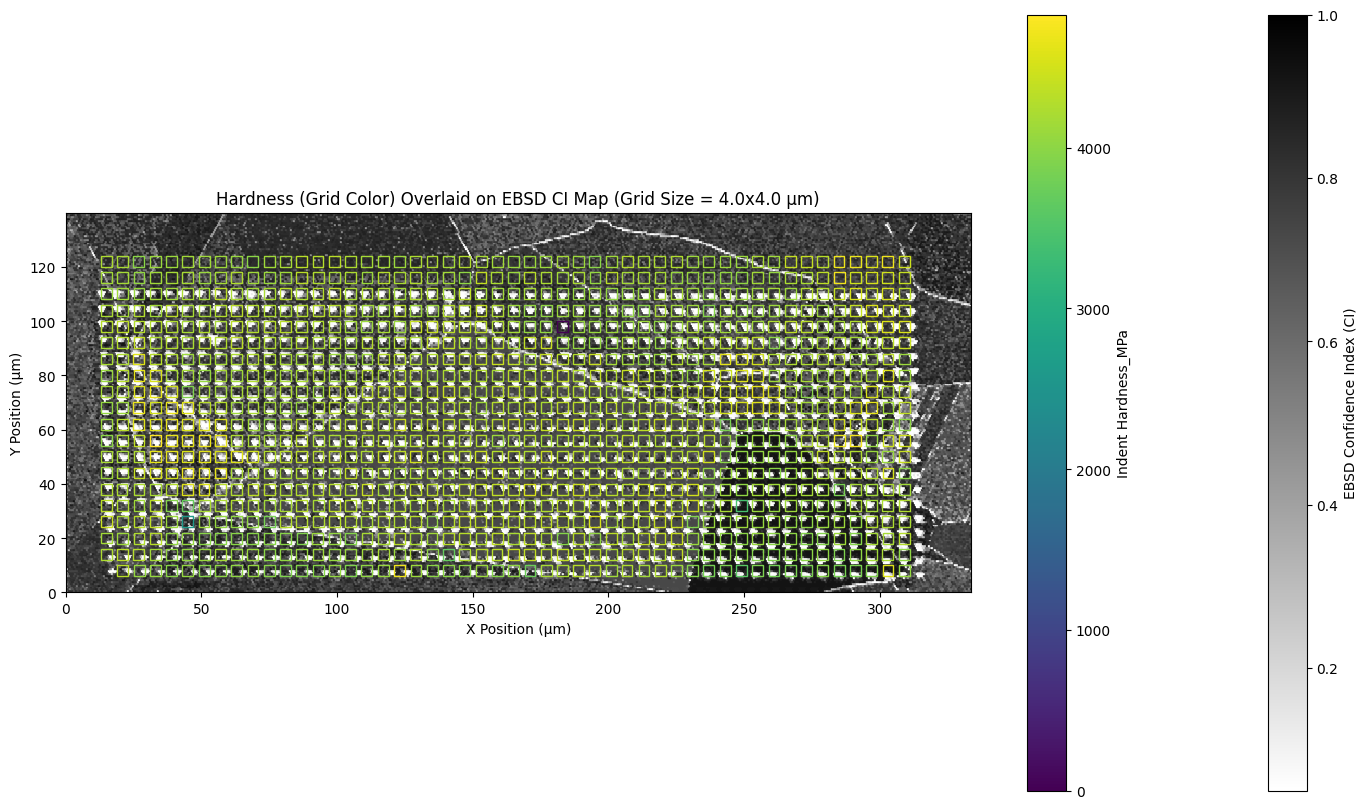


--- Starting local grid analysis for all indents (WITH OFFSETS) ---
Using a grid size of 4.0 (width) x 5.0 (height) µm for all indents.
Using X_OFFSET: 846.992 and Y_OFFSET: -5575.945

--- Analysis Complete ---
Local EBSD statistics have been merged with nano-indentation data.

Successfully saved final correlated data to 'correlated_nano_ebsd_data.csv'

--- Generating Spatial Correlation Map with Grid Outlines ---
Plotting with 4.0x5.0 µm grids.
Plotting EBSD background map...
Overlaying hardness grid boxes...

Spatial correlation map saved to 'spatial_correlation_map_WITH_GRIDS_5x4.png'


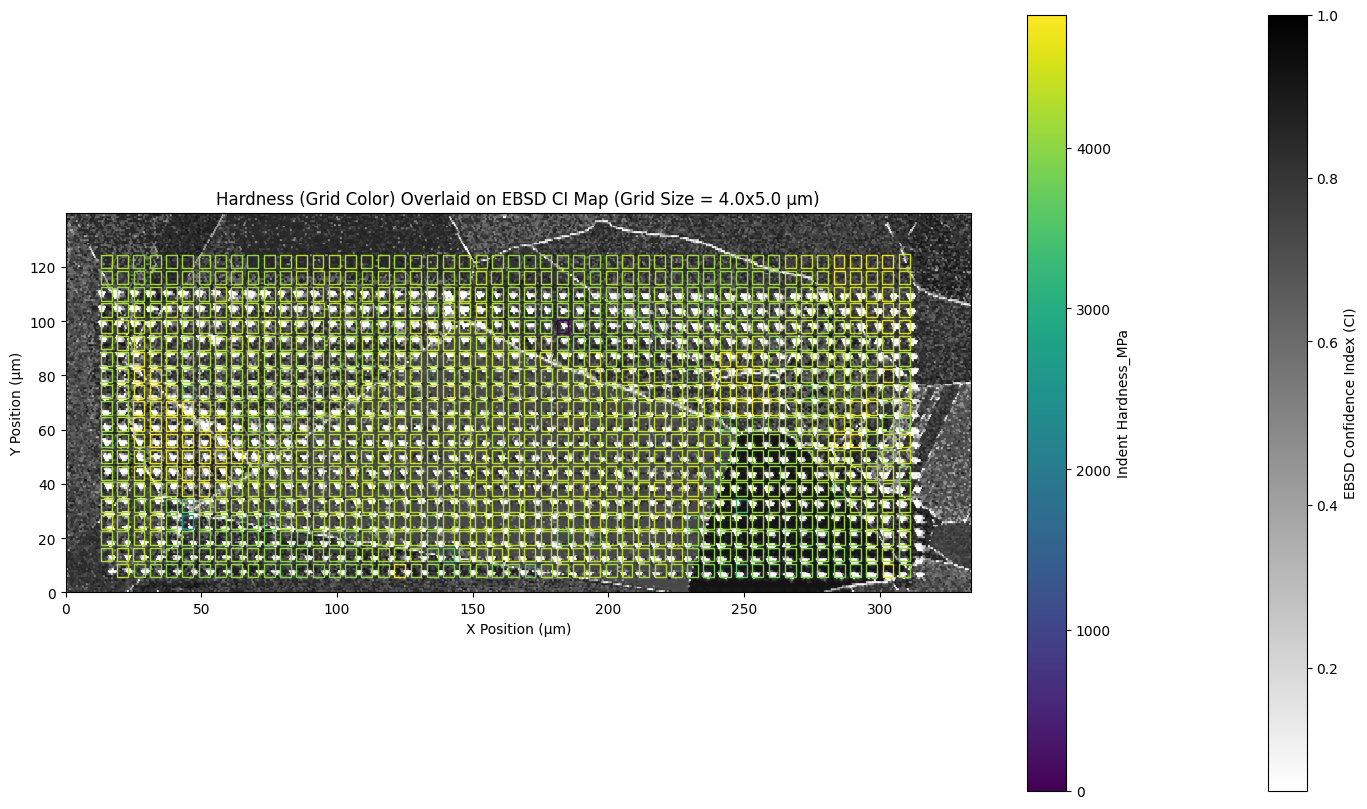

In [25]:
# --- This cell combines the logic from Cells 4, 5, and 8 ---
#
# It defines the analysis function, runs it on all indents,
# and then plots the final spatial map.
#
# *** MODIFIED to use a 5x4 µm grid ***
#
# Make sure you have run Cell 2 (load ebsd_map_df)
# and Cell 3 (load nano_summary_df) before this!
#
# -----------------------------------------------------------

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

# --- Part 1: Define the "Grid" Analysis Function (from old Cell 4) ---

def analyze_local_grid(center_x, center_y, box_width, box_height, ebsd_df): # <-- MODIFIED
    """
    Analyzes the local EBSD data within a rectangular grid centered at (center_x, center_y).
    """
    
    # --- DEFINE YOUR COLUMN NAMES HERE ---
    X_COL = 'x'         # The column name for X-coordinates in ebsd_map_df
    Y_COL = 'y'         # The column name for Y-coordinates in ebsd_map_df
    CI_COL = 'CI'       # The column name for Confidence Index
    IQ_COL = 'IQ'       # The column name for Image Quality
    EULER1_COL = 'phi1' # The column name for the first Euler angle
    EULER2_COL = 'PHI'  # The column name for the second Euler angle (uppercase)
    EULER3_COL = 'phi2' # The column name for the third Euler angle
    # ----------------------------------------------------
    
    try:
        # --- MODIFIED: Use separate half_width and half_height ---
        half_width = box_width / 2.0
        half_height = box_height / 2.0
        
        # Define the boundaries of the grid
        x_min = center_x - half_width
        x_max = center_x + half_width
        y_min = center_y - half_height
        y_max = center_y + half_height
        # ---------------------------------------------------------
        
        # "Crop" the main EBSD map
        local_grid_df = ebsd_df[
            (ebsd_df[X_COL] >= x_min) & (ebsd_df[X_COL] <= x_max) &
            (ebsd_df[Y_COL] >= y_min) & (ebsd_df[Y_COL] <= y_max)
        ].copy()
        
        # --- Calculate Local Statistics ---
        if local_grid_df.empty:
            return pd.Series({
                'local_points_count': 0,
                'local_avg_CI': np.nan,
                'local_avg_IQ': np.nan,
                'local_std_Euler1': np.nan,
                'local_std_Euler2': np.nan,
                'local_std_Euler3': np.nan
            })

        points_count = local_grid_df.shape[0]
        avg_ci = local_grid_df[CI_COL].mean()
        avg_iq = local_grid_df[IQ_COL].mean()
        std_euler1 = local_grid_df[EULER1_COL].std()
        std_euler2 = local_grid_df[EULER2_COL].std()
        std_euler3 = local_grid_df[EULER3_COL].std()
        
        results = pd.Series({
            'local_points_count': points_count,
            'local_avg_CI': avg_ci,
            'local_avg_IQ': avg_iq,
            'local_std_Euler1': std_euler1,
            'local_std_Euler2': std_euler2,
            'local_std_Euler3': std_euler3
        })
        
        return results

    except KeyError as e:
        print(f"--- A KeyError occurred in 'analyze_local_grid' ---")
        print(f"Error: The column name {e} was not found in your EBSD DataFrame.")
        print("Your available columns are:")
        print(ebsd_df.columns.to_list())
        return pd.Series(dtype='float64') # Return empty series on error

# --- Part 2: Run Analysis for All Indents (from old Cell 5) ---
print("\n--- Starting local grid analysis for all indents (WITH OFFSETS) ---")

# !!! These are your final, correct offsets !!!
X_OFFSET = 846.992  # <--- YOUR NEW X-VALUE
Y_OFFSET = -5575.945 # <--- YOUR NEW Y-VALUE
# --------------------------------------------------

# --- MODIFIED: Define separate Width and Height ---
GRID_WIDTH_UM = 4.0  # 5µm in X-direction
GRID_HEIGHT_UM = 5.0 # 4µm in Y-direction
# --------------------------------------------------

if 'nano_summary_df' in locals() and 'ebsd_map_df' in locals():
    # --- MODIFIED: Updated print statement ---
    print(f"Using a grid size of {GRID_WIDTH_UM} (width) x {GRID_HEIGHT_UM} (height) µm for all indents.")
    print(f"Using X_OFFSET: {X_OFFSET} and Y_OFFSET: {Y_OFFSET}")
    
    local_stats_df = nano_summary_df.apply(
        lambda row: analyze_local_grid(
            row['PosX_um'] + X_OFFSET,  # <-- Added offset
            row['PosY_um'] + Y_OFFSET,  # <-- Added offset
            GRID_WIDTH_UM,              # <-- MODIFIED: Pass width
            GRID_HEIGHT_UM,             # <-- MODIFIED: Pass height
            ebsd_map_df
        ),
        axis=1 # Apply the function row-wise
    )
    
    # --- Merge the results ---
    final_df = pd.concat([nano_summary_df, local_stats_df], axis=1)
    
    print("\n--- Analysis Complete ---")
    print("Local EBSD statistics have been merged with nano-indentation data.")
    
    # Save the final correlated data to a new file
    output_csv = 'correlated_nano_ebsd_data.csv'
    final_df.to_csv(output_csv, index=True)
    print(f"\nSuccessfully saved final correlated data to '{output_csv}'")
    
    # --- Part 3: Plot Spatial Map (from old Cell 8) ---
    print("\n--- Generating Spatial Correlation Map with Grid Outlines ---")
    
    try:
        # --- MODIFIED: Use width and height (Grid_size_um removed) ---
        X_COL = 'PosX_um'
        Y_COL = 'PosY_um'
        HARDNESS_COL = 'Hardness_MPa'
        
        if not all(col in final_df.columns for col in [X_COL, Y_COL, HARDNESS_COL]):
            print(f"ERROR: One or more columns ({X_COL}, {Y_COL}, {HARDNESS_COL}) not in final_df!")
            raise ValueError("Missing required columns in final_df")

        # --- MODIFIED: Calculate half-dimensions ---
        half_width = GRID_WIDTH_UM / 2.0
        half_height = GRID_HEIGHT_UM / 2.0
        print(f"Plotting with {GRID_WIDTH_UM}x{GRID_HEIGHT_UM} µm grids.")

        plt.figure(figsize=(15, 10))
        ax = plt.gca()
        
        print("Plotting EBSD background map...")
        bg = ax.scatter(
            ebsd_map_df['x'], ebsd_map_df['y'], c=ebsd_map_df['CI'], 
            cmap='gray_r', s=1, marker='s', vmin=0.05, vmax=1.0
        )
        plt.colorbar(bg, label='EBSD Confidence Index (CI)', ax=ax, shrink=0.8)
        
        print("Overlaying hardness grid boxes...")
        norm = plt.Normalize(final_df[HARDNESS_COL].min(), final_df[HARDNESS_COL].max())
        cmap = plt.get_cmap('viridis')
        
        for index, row in final_df.iterrows():
            center_x = row[X_COL] + X_OFFSET
            center_y = row[Y_COL] + Y_OFFSET
            color = cmap(norm(row[HARDNESS_COL]))
            
            # --- MODIFIED: Calculate bottom-left corner (x_min, y_min) ---
            x_min = center_x - half_width
            y_min = center_y - half_height
            
            # --- MODIFIED: Use width and height in patches.Rectangle ---
            rect = patches.Rectangle(
                (x_min, y_min), GRID_WIDTH_UM, GRID_HEIGHT_UM, 
                linewidth=1.0, edgecolor=color, facecolor='none'
            )
            ax.add_patch(rect)
        
        sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
        sm.set_array([])
        plt.colorbar(sm, label=f'Indent {HARDNESS_COL}', ax=ax, shrink=0.8)

        ax.set_xlabel('X Position (µm)')
        ax.set_ylabel('Y Position (µm)')
        # --- MODIFIED: Updated title ---
        ax.set_title(f'Hardness (Grid Color) Overlaid on EBSD CI Map (Grid Size = {GRID_WIDTH_UM}x{GRID_HEIGHT_UM} µm)')
        ax.set_xlim(ebsd_map_df['x'].min(), ebsd_map_df['x'].max())
        ax.set_ylim(ebsd_map_df['y'].min(), ebsd_map_df['y'].max())
        ax.set_aspect('equal', adjustable='box')
        plt.tight_layout()
        
        plot_filename = 'spatial_correlation_map_WITH_GRIDS_5x4.png' # <-- Changed filename
        plt.savefig(plot_filename, dpi=300, bbox_inches='tight') # <-- Save the file
        print(f"\nSpatial correlation map saved to '{plot_filename}'")
        
        plt.show() # <-- Show the plot in the notebook
        plt.close() # Close plot to save memory

    except Exception as e:
        print(f"\n--- AN UNEXPECTED ERROR OCCURRED DURING PLOTTING ---")
        print(e)
else:
    print("\n--- ERROR ---")
    print("Cannot run analysis: 'nano_summary_df' or 'ebsd_map_df' not loaded.")
    print("Please ensure Cells 2 and 3 ran successfully before running this cell.")